# TALLER 3 — SIMULACIÓN MONTECARLO
## AgroLens AI: Plataforma SaaS de Visión Computacional para Control de Calidad Agroexportador

**Curso:** Evaluación Financiera de Proyectos — Maestría en Ciencia de Datos & IA (UTEC)
**Alumno:** Sebastián López
**Entregable:** `Lopez_Taller3.ipynb` (complementa `Lopez_Taller3.xlsx`)

---

**El caso.** AgroLens AI vende por **suscripción anual (USD 30,000 por línea de empaque)** un sistema de visión
computacional que detecta defectos de calidad (hongos, deshidratado, calibre) en líneas de empaque de arándano y
uva de mesa. Monetización **directa**. El caso base (mismo del Excel): CAPEX \$600k + \$60k de capital de trabajo,
25 líneas suscritas en el Año 1, costo variable \$8k/línea, costos fijos \$250k/año, crecimiento neto 15% anual,
WACC 16%, IR 29.5%, horizonte 5 años.

**Objetivo del notebook:** pasar de 3 escenarios discretos a **10,000 escenarios continuos** y responder:
1. ¿P(VPN > \$1M)?
2. ¿P10?
3. ¿Cuál es la variable crítica?

In [1]:
# ============================================================================
# 1. LIBRERÍAS Y CONFIGURACIÓN
# ============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)  # Reproducibilidad

print("="*70)
print("TALLER 3: MONTECARLO - AGROLENS AI (SaaS Vision Computacional Agro)")
print("="*70)
print("Librerías importadas correctamente")

TALLER 3: MONTECARLO - AGROLENS AI (SaaS Vision Computacional Agro)
Librerías importadas correctamente


## 2. Parámetros base y distribuciones

Los parámetros deterministas replican el Tab 1 del Excel. Para las variables inciertas se usó el criterio de la
Sesión 7: **Normal** cuando hay datos/benchmark histórico, **Triangular** cuando hay 3 estimados de expertos
(min/moda/max) y **Uniforme** cuando no hay información previa.

| Variable | Distribución | Parámetros | Justificación |
|---|---|---|---|
| Precio suscripción | Normal | μ=\$30,000, σ=\$2,500 | Benchmark de pricing en pilotos; dispersión por negociación |
| Líneas suscritas Año 1 | Triangular | min=17, moda=25, max=32 | Estimados del pipeline comercial (peor/probable/mejor) |
| Costo variable/línea | Triangular | min=\$7,000, moda=\$8,000, max=\$10,500 | Cotizaciones hardware+cloud; cola derecha por HITL |
| Crecimiento bruto anual | Triangular | min=15%, moda=25%, max=35% | Estimados de expansión comercial |
| Churn anual | Uniforme | 5% – 15% | Sin historia propia: rango amplio equiprobable |
| CAPEX | Normal | μ=\$600k, σ=\$60k | Presupuesto de desarrollo con incertidumbre de ±10% |

Nota de consistencia: el crecimiento **neto** base del Excel (15%) = moda del crecimiento bruto (25%) − media del churn (10%).

In [2]:
# ============================================================================
# 2. PARÁMETROS DEL MODELO (idénticos al Tab 1 del Excel)
# ============================================================================
N_SIM   = 10_000      # iteraciones Montecarlo
HORIZON = 5           # años
WACC    = 0.16
TAX     = 0.295       # IR Perú
WC      = 60_000      # capital de trabajo (año 0, se recupera año 5)
CFIJO   = 250_000     # costos fijos anuales
RES_PCT = 0.10        # valor residual % CAPEX

# --- Caso base determinista (para validar contra el Excel) ---
BASE = dict(precio=30_000, vol1=25, cvar=8_000, g_neto=0.15, capex=600_000)

def vpn_proyecto(precio, vol1, cvar, g_neto, capex):
    """FCF 5 años -> VPN. Misma lógica que el Excel:
    FCF_t = EBIT - max(0, EBIT*tax) + Dep  (+ residual + WC en t=5)"""
    dep = capex / HORIZON
    res = capex * RES_PCT
    vpn = -(capex + WC)
    for t in range(1, HORIZON + 1):
        unidades = vol1 * (1 + g_neto) ** (t - 1)
        ebit = unidades * (precio - cvar) - CFIJO - dep
        fcf  = ebit - max(0, ebit * TAX) + dep
        if t == HORIZON:
            fcf += res + WC
        vpn += fcf / (1 + WACC) ** t
    return vpn

vpn_base = vpn_proyecto(**BASE)
print(f"VPN caso base: ${vpn_base:,.0f}   (Excel Tab 1: $578,717 -> debe coincidir)")

# ============================================================================
# GENERACIÓN DE VARIABLES ALEATORIAS (10,000 escenarios)
# ============================================================================
rng = np.random.default_rng(42)

precio = rng.normal(30_000, 2_500, N_SIM)
vol1   = rng.triangular(17, 25, 32, N_SIM)
cvar   = rng.triangular(7_000, 8_000, 10_500, N_SIM)
crec   = rng.triangular(0.15, 0.25, 0.35, N_SIM)   # crecimiento bruto
churn  = rng.uniform(0.05, 0.15, N_SIM)            # churn anual
capex  = np.clip(rng.normal(600_000, 60_000, N_SIM), 420_000, None)
g_neto = crec - churn                               # crecimiento neto de líneas

print(f"\n{N_SIM:,} escenarios generados para 6 variables inciertas")
print(f"   Precio:      media=${precio.mean():,.0f}, sd=${precio.std():,.0f}")
print(f"   Líneas Año1: media={vol1.mean():.1f}")
print(f"   Costo var:   media=${cvar.mean():,.0f}")
print(f"   Crec. neto:  media={g_neto.mean():.1%}")
print(f"   CAPEX:       media=${capex.mean():,.0f}")

VPN caso base: $578,717   (Excel Tab 1: $578,717 -> debe coincidir)

10,000 escenarios generados para 6 variables inciertas
   Precio:      media=$29,974, sd=$2,516
   Líneas Año1: media=24.7
   Costo var:   media=$8,505
   Crec. neto:  media=15.0%
   CAPEX:       media=$599,530


In [3]:
# ============================================================================
# 3. SIMULACIÓN MONTECARLO (vectorizada)
# ============================================================================
dep = capex / HORIZON
res = capex * RES_PCT
vpns = -(capex + WC).astype(float)

for t in range(1, HORIZON + 1):
    unidades = vol1 * (1 + g_neto) ** (t - 1)
    ebit = unidades * (precio - cvar) - CFIJO - dep
    fcf  = ebit - np.maximum(0, ebit * TAX) + dep
    if t == HORIZON:
        fcf += res + WC
    vpns += fcf / (1 + WACC) ** t

print(f"Simulación completada: {len(vpns):,} VPNs calculados")
print("Primeros 5 escenarios:", [f"${v:,.0f}" for v in vpns[:5]])

Simulación completada: 10,000 VPNs calculados
Primeros 5 escenarios: ['$962,823', '$-24,872', '$1,042,477', '$495,886', '$84,750']


In [4]:
# ============================================================================
# 4. ESTADÍSTICAS, MÉTRICAS DE RIESGO Y RESPUESTAS DEL TALLER
# ============================================================================
media, mediana, sd = vpns.mean(), np.median(vpns), vpns.std()
cv = sd / media
p_pos  = (vpns > 0).mean() * 100
p_1m   = (vpns > 1_000_000).mean() * 100
pcts   = np.percentile(vpns, [5, 10, 25, 50, 75, 90, 95])
var95  = np.percentile(vpns, 5)
cvar95 = vpns[vpns <= var95].mean()

print("="*70)
print("RESULTADOS MONTECARLO - AGROLENS AI")
print("="*70)
print(f"E(VPN):                 ${media:>12,.0f}")
print(f"Mediana:                ${mediana:>12,.0f}")
print(f"Desviación estándar:    ${sd:>12,.0f}")
print(f"CV:                     {cv:>13.2f}")
print(f"P(VPN > 0):             {p_pos:>12.1f}%")
print(f"P(VPN > $1M):           {p_1m:>12.1f}%   <- PREGUNTA 1")
print("-"*70)
for p, v in zip([5,10,25,50,75,90,95], pcts):
    flag = "   <- PREGUNTA 2 (P10)" if p == 10 else ""
    print(f"P{p:02d}:                    ${v:>12,.0f}{flag}")
print("-"*70)
print(f"VaR 95%:                ${var95:>12,.0f}")
print(f"CVaR 95%:               ${cvar95:>12,.0f}")

# Correlaciones variable -> VPN (variable crítica)
variables = {'Líneas Año 1': vol1, 'Precio suscripción': precio, 'Crecimiento bruto': crec,
             'Churn anual': churn, 'CAPEX': capex, 'Costo variable': cvar}
corrs = {k: np.corrcoef(v, vpns)[0, 1] for k, v in variables.items()}
corrs = dict(sorted(corrs.items(), key=lambda x: abs(x[1]), reverse=True))

print("\nCORRELACIÓN DE CADA VARIABLE CON EL VPN:")
for k, v in corrs.items():
    print(f"   {k:<22} {v:+.3f}")
critica = list(corrs)[0]
print(f"\nVARIABLE CRÍTICA: {critica} (r = {corrs[critica]:+.3f})   <- PREGUNTA 3")

RESULTADOS MONTECARLO - AGROLENS AI
E(VPN):                 $     526,138
Mediana:                $     506,339
Desviación estándar:    $     315,981
CV:                              0.60
P(VPN > 0):                     96.5%
P(VPN > $1M):                    7.3%   <- PREGUNTA 1
----------------------------------------------------------------------
P05:                    $      39,104
P10:                    $     134,694   <- PREGUNTA 2 (P10)
P25:                    $     305,391
P50:                    $     506,339
P75:                    $     729,633
P90:                    $     938,077
P95:                    $   1,074,125
----------------------------------------------------------------------
VaR 95%:                $      39,104
CVaR 95%:               $     -61,179

CORRELACIÓN DE CADA VARIABLE CON EL VPN:
   Líneas Año 1           +0.625
   Precio suscripción     +0.597
   Crecimiento bruto      +0.359
   Churn anual            -0.258
   Costo variable         -0.175
   CAPE

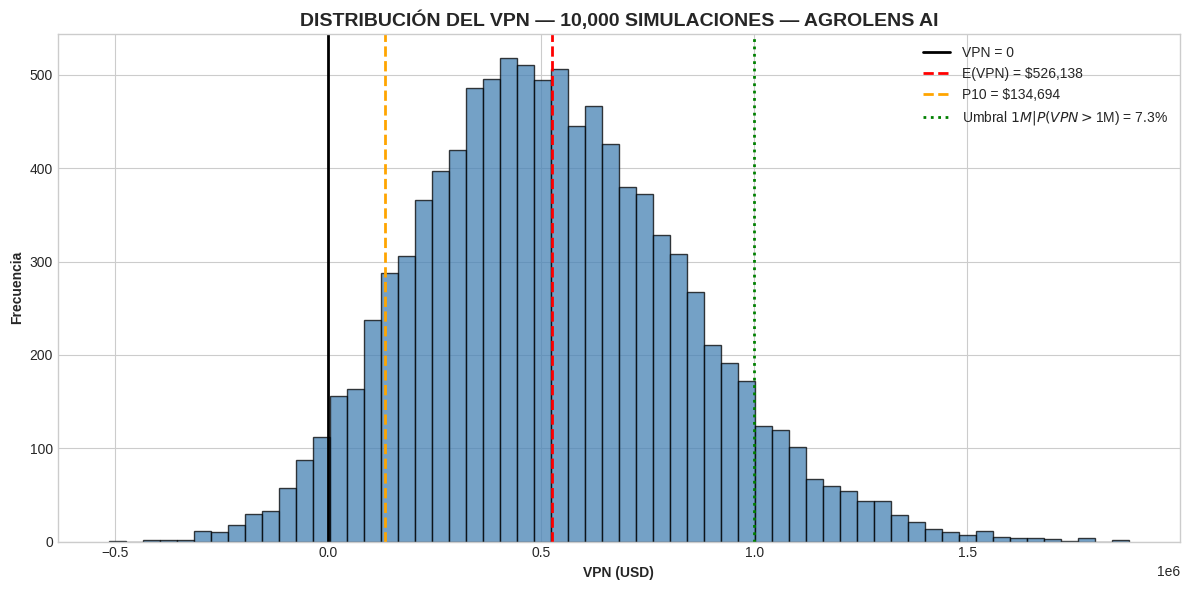

In [5]:
# ============================================================================
# 5. HISTOGRAMA DE LA DISTRIBUCIÓN DEL VPN
# ============================================================================
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(vpns, bins=60, color='steelblue', edgecolor='black', alpha=0.75)
ax.axvline(0, color='black', lw=2, label='VPN = 0')
ax.axvline(media, color='red', ls='--', lw=2, label=f'E(VPN) = ${media:,.0f}')
ax.axvline(pcts[1], color='orange', ls='--', lw=2, label=f'P10 = ${pcts[1]:,.0f}')
ax.axvline(1_000_000, color='green', ls=':', lw=2, label=f'Umbral $1M  |  P(VPN>$1M) = {p_1m:.1f}%')
ax.set_xlabel('VPN (USD)', fontweight='bold')
ax.set_ylabel('Frecuencia', fontweight='bold')
ax.set_title(f'DISTRIBUCIÓN DEL VPN — {N_SIM:,} SIMULACIONES — AGROLENS AI',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

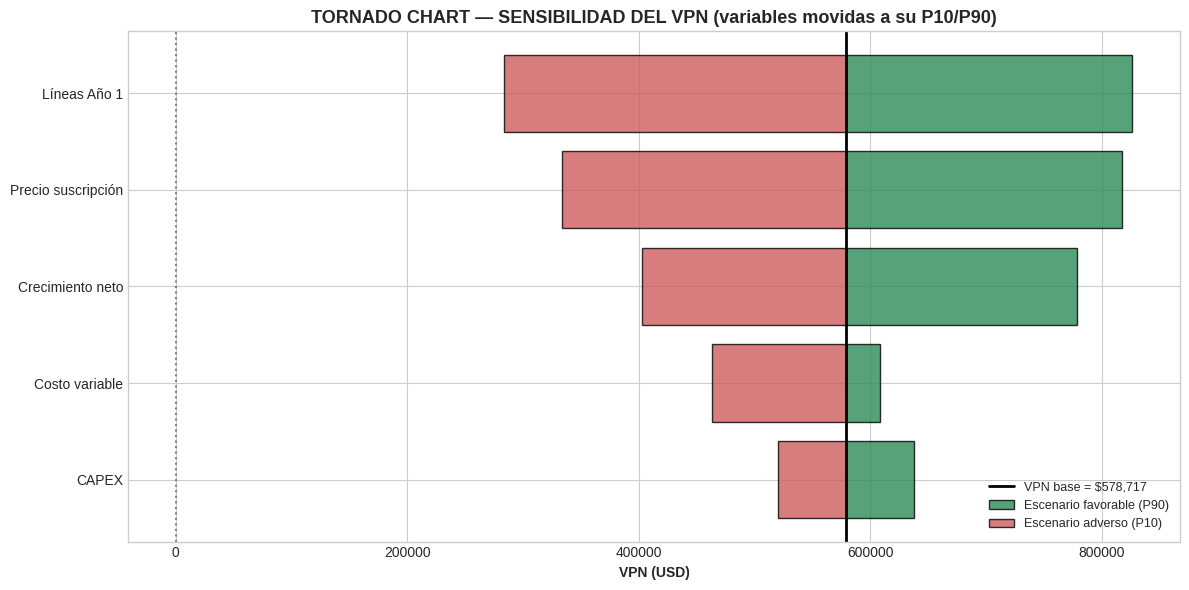

          Variable      VPN_bajo      VPN_alto    Rango
      Líneas Año 1 283563.336006 826236.906458 $542,674
Precio suscripción 333464.939570 817629.909092 $484,165
  Crecimiento neto 402680.235337 778266.491920 $375,586
    Costo variable 462960.496361 608481.585632 $145,521
             CAPEX 520599.996121 637642.650614 $117,043


In [6]:
# ============================================================================
# 6. TORNADO CHART - VARIABLES CRÍTICAS
# ============================================================================
# Método complementario al de correlaciones: se mueve UNA variable a su P10 y P90
# (manteniendo el resto en base) y se mide el rango de VPN que genera.
tornado_specs = {
    'Líneas Año 1':        ('vol1',   np.percentile(vol1, 10),   np.percentile(vol1, 90)),
    'Precio suscripción':  ('precio', np.percentile(precio, 10), np.percentile(precio, 90)),
    'Crecimiento neto':    ('g_neto', np.percentile(g_neto, 10), np.percentile(g_neto, 90)),
    'Costo variable':      ('cvar',   np.percentile(cvar, 90),   np.percentile(cvar, 10)),
    'CAPEX':               ('capex',  np.percentile(capex, 90),  np.percentile(capex, 10)),
}
base_kw = dict(BASE); base_kw['g_neto'] = 0.15
rows = []
for nombre, (arg, lo, hi) in tornado_specs.items():
    kw_lo = dict(base_kw); kw_lo[arg] = lo
    kw_hi = dict(base_kw); kw_hi[arg] = hi
    v_lo, v_hi = vpn_proyecto(**kw_lo), vpn_proyecto(**kw_hi)
    rows.append((nombre, v_lo, v_hi, abs(v_hi - v_lo)))
tornado = pd.DataFrame(rows, columns=['Variable', 'VPN_bajo', 'VPN_alto', 'Rango']) \
            .sort_values('Rango')

fig, ax = plt.subplots(figsize=(12, 6))
for i, r in enumerate(tornado.itertuples()):
    ax.barh(i, r.VPN_alto - vpn_base, left=vpn_base, color='seagreen', alpha=0.8,
            edgecolor='black', label='Escenario favorable (P90)' if i == 0 else None)
    ax.barh(i, r.VPN_bajo - vpn_base, left=vpn_base, color='indianred', alpha=0.8,
            edgecolor='black', label='Escenario adverso (P10)' if i == 0 else None)
ax.axvline(vpn_base, color='black', lw=2, label=f'VPN base = ${vpn_base:,.0f}')
ax.axvline(0, color='gray', ls=':')
ax.set_yticks(range(len(tornado)))
ax.set_yticklabels(tornado['Variable'])
ax.set_xlabel('VPN (USD)', fontweight='bold')
ax.set_title('TORNADO CHART — SENSIBILIDAD DEL VPN (variables movidas a su P10/P90)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

print(tornado.sort_values('Rango', ascending=False)
      .assign(Rango=lambda d: d['Rango'].map('${:,.0f}'.format)).to_string(index=False))

## 7. Respuestas del taller y conclusión

*(Los valores exactos aparecen en las salidas de las celdas 4–6; con `seed=42` son reproducibles.)*

**1. ¿P(VPN > \$1M)?** ≈ **7%**. El proyecto rara vez supera \$1M en 5 años: para capturar ese upside se
necesitaría el escenario optimista comercial (≥31 líneas, precio ≥\$34k), lo que refuerza que el valor está en
escalar volumen.

**2. ¿P10?** ≈ **+\$135k** (positivo). En el 10% peor de los casos el proyecto aún crea valor. 

**3. ¿Variable crítica?** **Líneas suscritas Año 1** (r ≈ +0.62), seguida de cerca por el **precio**
(r ≈ +0.60). Ambas son variables **comerciales**, no técnicas. CAPEX y costo variable son
secundarios (|r| < 0.2).

**Decisión (se detalla en el slide):** **GO CONDICIONAL** — P(VPN>0) ≈ 96% y P10 positivo apoyan el GO;
el CV de escenarios (1.37) y un pesimista de −\$531k exigen validar el pipeline comercial (≥17 LOIs y pilotos
pagados) antes de liberar el CAPEX completo.